# Assignment 1 — EDA ve Baseline Modeller
**XACLE Challenge 2027** (IEEE ICASSP 2027 – The 2nd X-to-Audio Alignment Challenge)

Görev: Bir ses kaydı ile metin açıklaması arasındaki anlamsal uyum için insanların verdiği puanı tahmin etmek.

İçerik:
1. Kurulum
2. Veri kümesine genel bakış
3. Puan dağılımı
4. Dinleyiciler arası tutarlılık
5. Ses üretim modellerine göre analiz
6. Metin analizi
7. Ses analizi
8. Baseline modeller

## 1. Kurulum

In [1]:
import sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or Path("/content").exists()
REPO_URL = "https://github.com/deafiduck/.-XACLE-IEEE-ICASSP-2027---The-2nd-X-to-Audio-Alignment-Challenge-.git"

if IN_COLAB:
    REPO_DIR = Path("/content/repo")
    if REPO_DIR.exists():
        subprocess.run(["git", "-C", str(REPO_DIR), "pull"], check=True)
    else:
        subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
else:
    REPO_DIR = Path.cwd()

sys.path.insert(0, str(REPO_DIR))
print("IN_COLAB:", IN_COLAB, "| REPO_DIR:", REPO_DIR)

IN_COLAB: True | REPO_DIR: /content/repo


In [2]:

DATASET = "XACLE_Challenge_2027_development_dataset"

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    LOCAL_DIR = Path("/content/data")
    DATA_ROOT = LOCAL_DIR / DATASET
    if not DATA_ROOT.exists():
        candidates = [Path("/content/drive/MyDrive/Colab Notebooks/XACLE"),
                      Path("/content/drive/MyDrive/XACLE")]
        zip_path = next((d / f"{DATASET}.zip" for d in candidates
                         if (d / f"{DATASET}.zip").exists()), None)
        if zip_path is None:
            raise FileNotFoundError(f"{DATASET}.zip şu klasörlerde bulunamadı: {candidates}")
        LOCAL_DIR.mkdir(parents=True, exist_ok=True)
        print("Kopyalanıyor:", zip_path)
        subprocess.run(["cp", str(zip_path), str(LOCAL_DIR)], check=True)
        print("Açılıyor...")
        subprocess.run(["unzip", "-q", "-o", str(LOCAL_DIR / zip_path.name),
                        "-x", "__MACOSX/*", "-d", str(LOCAL_DIR)], check=True)
        (LOCAL_DIR / zip_path.name).unlink()
else:
    DATA_ROOT = REPO_DIR / "datasets" / DATASET

print(DATA_ROOT, "| bulundu:", DATA_ROOT.exists())

Mounted at /content/drive
Kopyalanıyor: /content/drive/MyDrive/XACLE/XACLE_Challenge_2027_development_dataset.zip
Açılıyor...
/content/data/XACLE_Challenge_2027_development_dataset | bulundu: True


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

from src.data import (load_metadata, load_all, audio_path, audio_info,
                      FILE_COL, TEXT_COL, MODEL_COL, LISTENER_COL, SCORE_COL, SPLITS)
from src.utils import compute_metrics
from src.models import MeanBaseline

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

## 2. Veri kümesine genel bakış
Her örnek (instance) bir **(ses, metin)** çiftidir. Öznitelikler: ses dosyası (sayısal sinyal), metin açıklaması (string), üretici model (kategorik). Hedef değişken: ortalama uyum puanı (sayısal).

In [4]:
df = load_all(DATA_ROOT, average=True)          # ses başına ortalama puan
df_l = load_all(DATA_ROOT, average=False)       # dinleyici bazlı puanlar

print(df.groupby("split").size())
df.head()

split
test          3000
train         7500
validation    3000
dtype: int64


,wav_file_name,text,score,model_id,model_name,split
0,00000.wav,A water vehicle travels through the water with wind noise and a man talking,8.00,0,audiocaps,train
1,00001.wav,A motorcycle drives by,7.50,3,audioldm2,train
2,00002.wav,Some liquid flows followed by something sink,7.50,6,tango,train
3,00003.wav,Rain falling with distant thunder roaring,9.25,1,audiogen,train
4,00004.wav,The propellers of a helicopter scream as someone yells,2.00,6,tango,train


In [5]:
df.info()
print("\nEksik değerler:\n", df.isna().sum())
print("\nTekrar eden satır:", df.duplicated().sum())
print("Tekrar eden dosya adı:", df[FILE_COL].duplicated().sum())
print("Tekrar eden metin:", df[TEXT_COL].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13500 entries, 0 to 13499
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   wav_file_name  13500 non-null  object 
 1   text           13500 non-null  object 
 2   score          13500 non-null  float64
 3   model_id       13500 non-null  int64  
 4   model_name     13500 non-null  object 
 5   split          13500 non-null  object 
dtypes: float64(1), int64(1), object(4)
memory usage: 632.9+ KB

Eksik değerler:
 wav_file_name    0
text             0
score            0
model_id         0
model_name       0
split            0
dtype: int64

Tekrar eden satır: 0
Tekrar eden dosya adı: 0
Tekrar eden metin: 9064


In [6]:
score_summary = (
    df.groupby("split")[SCORE_COL]
      .agg(["count", "mean", "median", "std", "min", "max"])
      .reindex(SPLITS)
      .round(3)
)
print("Bölümlere göre puan özetleri:")
display(score_summary)
print("\n0–10 dışında kalan kayıtlar:", (~df[SCORE_COL].between(0, 10)).sum())
print("Genel ortalama:", round(df[SCORE_COL].mean(), 3))

Bölümlere göre puan özetleri:


,count,mean,median,std,min,max
split,,,,,,
train,7500,7.034,7.50,2.394,0.0,10.0
validation,3000,6.919,7.50,2.380,0.0,10.0
test,3000,7.155,7.75,2.259,0.0,10.0



0–10 dışında kalan kayıtlar: 0
Genel ortalama: 7.036


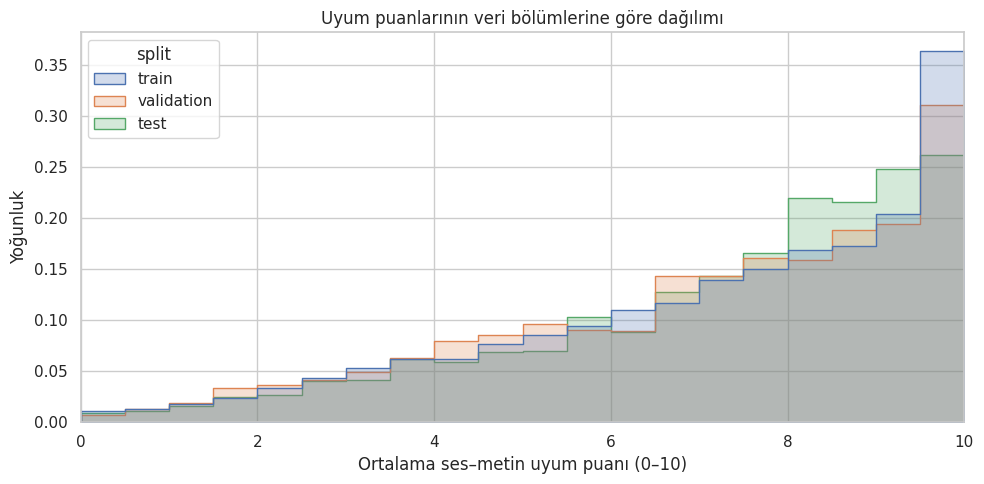

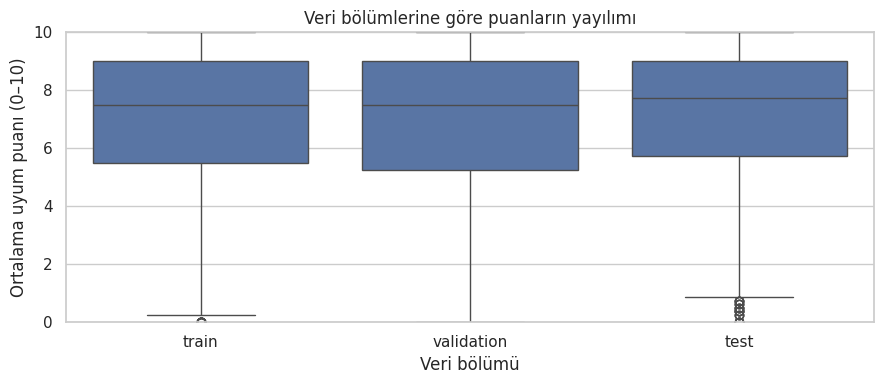

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=df, x=SCORE_COL, hue="split", hue_order=list(SPLITS),
             bins=20, stat="density", common_norm=False,
             element="step", alpha=0.25, ax=ax)
ax.set(xlim=(0, 10), xlabel="Ortalama ses–metin uyum puanı (0–10)",
       ylabel="Yoğunluk", title="Uyum puanlarının veri bölümlerine göre dağılımı")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=df, x="split", y=SCORE_COL, order=list(SPLITS), ax=ax)
ax.set(xlabel="Veri bölümü", ylabel="Ortalama uyum puanı (0–10)",
       title="Veri bölümlerine göre puanların yayılımı", ylim=(0, 10))
plt.tight_layout()
plt.show()

**Bulgular — veriye genel bakış**

- Veri kümesinde 13.500 örnek var: train 7.500, validation 3.000, test 3.000. Her örnek bir (ses, metin) çifti.
- **Öznitelik tipleri:**
  - `wav_file_name`: ses dosyasına referans
  - `text`: serbest metin (string)
  - `model_id` / `model_name`: kategori.
  - `score`: 0–10 arası (dinleyici puanlarının ortalaması)
- **Eksik değer yok**, tekrar eden satır ya da dosya adı da yok. Veri temizliği gerektirmiyor.
- **Tekrar eden metin sayısı 9.064**, yani 13.500 örnekte yalnızca 13.500 − 9.064 = 4.436 farklı açıklama var. Her açıklama ortalama ~3 farklı ses üretim modeliyle seslendirilmiş. Bunun iki sonucu var:
  - Aynı açıklama için farklı modellerin sesleri doğrudan karşılaştırılabilir.
  - Modeli değerlendirirken aynı açıklamanın hem eğitimde hem testte olmamasına dikkat etmek gerekir. Metni ezberleyen bir model yanıltıcı derecede iyi görünebilir.

4. Dinleyiciler arasındaki puan farklılıkları
Aynı ses için birden fazla insanın verdiği skorların ne kadar değiştiğini inceliyoruz.

In [8]:
# Ses başına verilen insan puanlarını
listener_spread = (
    #  aynı sesin puanları
    df_l.groupby(["split", FILE_COL])[SCORE_COL]
        # Kaç kişi puanlamış ve ortalama kaç
        .agg(n_listeners="count", mean_listener_score="mean",
             sd_listener="std", min_listener="min", max_listener="max")
        .reset_index()
)

listener_spread["score_range"] = (

    listener_spread["max_listener"] - listener_spread["min_listener"]
)

listener_summary = (
    # Her veri bölümünü ayrı topluyoruz.
    listener_spread.groupby("split")
      .agg(ses_sayisi=(FILE_COL, "size"),

           ortalama_dinleyici=("n_listeners", "mean"),

           ortalama_sd=("sd_listener", "mean"),

           ortalama_aralik=("score_range", "mean"))

      .reindex(SPLITS).round(3)
)

display(listener_summary)
# Hesaplanan bilgiyi ekrana yazdırıyoruz.
print("Birden az puanlayıcı içeren ses sayısı:", (listener_spread["n_listeners"] < 2).sum())


,ses_sayisi,ortalama_dinleyici,ortalama_sd,ortalama_aralik
split,,,,
train,7500,4.0,2.000,4.298
validation,3000,4.0,1.993,4.290
test,3000,8.0,2.032,5.530


Birden az puanlayıcı içeren ses sayısı: 0


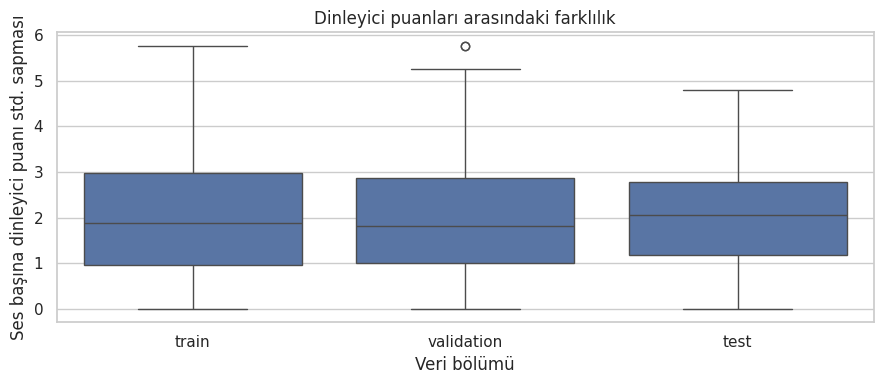

In [9]:

fig, ax = plt.subplots(figsize=(9, 4))
# Dinleyiciler arasındaki puan farklarının kutu grafiği
sns.boxplot(data=listener_spread, x="split", y="sd_listener",
            order=list(SPLITS), ax=ax)
ax.set(xlabel="Veri bölümü", ylabel="Ses başına dinleyici puanı std. sapması",
       # Grafik başlığını ekliyoruz.
       title="Dinleyici puanları arasındaki farklılık")

plt.tight_layout()

plt.show()


5. Ses üretici modellerine göre puanlar
Her üretici modelin ortalama puanını veri bölümlerine göre karşılaştırıyoruz.

n   mean  median    std
model_name     split                                 
audiocaps      test        1000  8.182   8.625  1.572
               train       2500  7.828   8.250  1.951
               validation  1000  7.680   8.250  2.079
audiogen       test         250  6.656   7.125  2.174
               train        750  6.385   6.750  2.321
               validation   250  6.366   6.750  2.328
audioldm       test         250  5.166   5.125  2.445
               train        500  5.580   5.750  2.598
               validation   250  5.504   5.625  2.353
audioldm2      test         250  5.980   6.062  2.444
               train        500  5.514   5.500  2.478
               validation   250  5.688   6.000  2.547
make-an-audio2 test         250  7.110   7.750  2.134
               train        750  7.288   7.750  2.122
               validation   250  7.490   7.750  1.887
stable_audio   test         250  6.264   6.875  2.621
               train        750  5.491   5.125  2.616
               validation   250  5.270   5.000  2.608
tango          test         250  6.149   6.438  2.271
               train        500  5.896   6.000  2.381
               validation   250  5.929   6.250  2.235
tango2         test         250  7.751   8.125  1.731
               train        500  8.000   8.500  1.737
               validation   250  7.776   8.000  1.696
tangoflux      test         250  8.063   8.500  1.568
               train        750  8.428   9.000  1.487
               validation   250  8.286   8.750  1.536

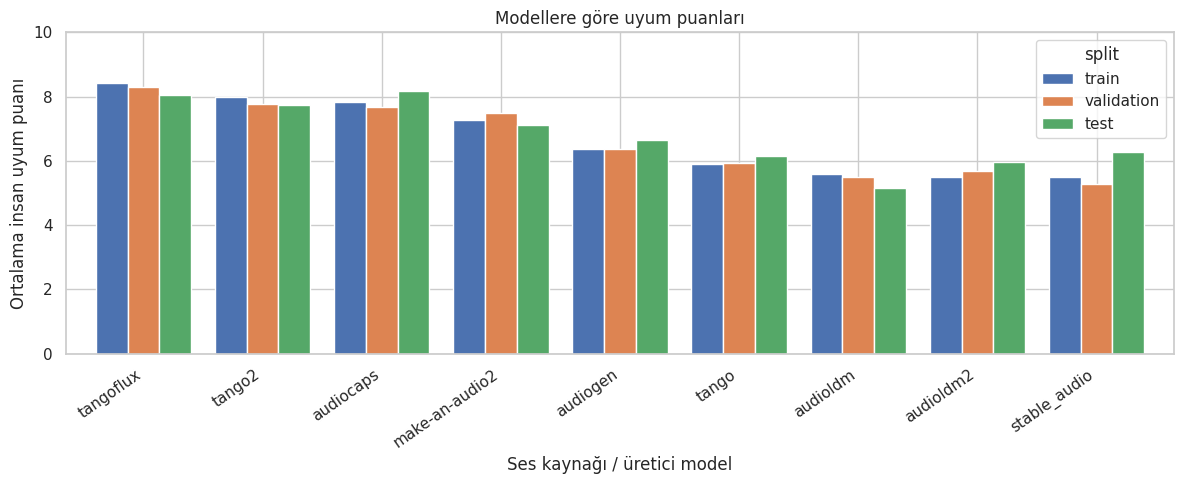

In [10]:
# Üretici modellerin puanları
generator_summary = (

    df.groupby([MODEL_COL, "split"])[SCORE_COL]
      # Kaç örnekvar ortalama, medyan ve sapma
      .agg(n="count", mean="mean", median="median", std="std")
      .round(3)
)
# Her ses üreticisinin özet puan tablosu
display(generator_summary)

# Grafik için ortalama puan tablosunu hazırlıyoruz.
means_by_model = (
    # Satırlara modelleri, sütunlara veri bölümlerini koyuyoruz.
    df.pivot_table(index=MODEL_COL, columns="split", values=SCORE_COL,
                   aggfunc="mean")
      .reindex(columns=SPLITS)
      # Modelleri eğitim ortalamasına göre sıralıyoruz.
      .sort_values("train", ascending=False)
)
# Modellerin puanlarını sütun grafikle çiziyoruz.
ax = means_by_model.plot(kind="bar", figsize=(12, 5), ylim=(0, 10), width=0.8)
ax.set(xlabel="Ses kaynağı / üretici model", ylabel="Ortalama insan uyum puanı",
       title="Modellere göre uyum puanları")

plt.xticks(rotation=35, ha="right")

plt.tight_layout()

plt.show()


6. Metin analizi
Metin uzunlukları, kelime sıklıkları ve farklı veri bölümleri arasındaki aynı açıklama tekrarları incelenir.

word_count                char_count                
                 mean median min max       mean median min  max
split                                                          
test            10.96   10.0   7  43      60.38   55.0  32  224
train            8.99    8.0   2  52      50.20   45.0  14  268
validation      10.23    9.0   2  31      58.25   52.0  14  177

train ∩ validation ortak metin sayısı: 11
train ∩ test ortak metin sayısı: 1
validation ∩ test ortak metin sayısı: 0


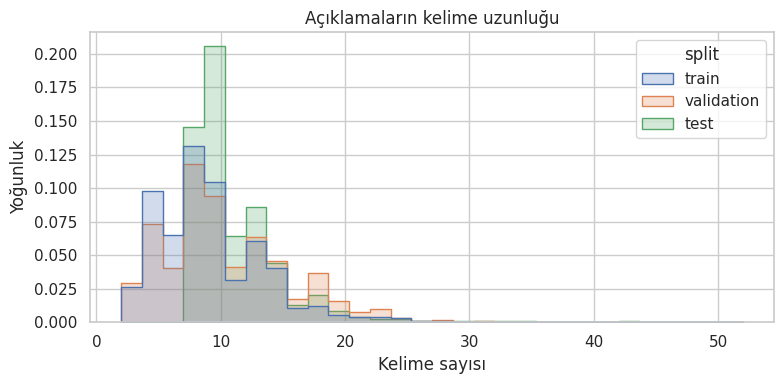

In [12]:
df_text = df.copy()#metin tablosu

df_text["word_count"] = df_text[TEXT_COL].astype(str).str.split().str.len()# metinler kaç kelime içeriyo
df_text["char_count"] = df_text[TEXT_COL].astype(str).str.len()

display(df_text.groupby("split")[["word_count", "char_count"]]
        .agg(["mean", "median", "min", "max"]).round(2))


text_sets = {}# Bölümlerin metinlerini ayrı ayrı saklamak için

for split_name in SPLITS:
    selected_texts = df_text.loc[df_text["split"] == split_name, TEXT_COL]

    text_sets[split_name] = set(selected_texts)# Aynı metinleri tekilleştirip sözlüğe koyuyoruz.
# Bölümleri ikili ikili karşılaştırıyoruz.
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    print(f"{a} ∩ {b} ortak metin sayısı:", len(text_sets[a] & text_sets[b]))


fig, ax = plt.subplots(figsize=(8, 4))
# Metin uzunluklarının histogramını oluşturuyoruz.
sns.histplot(data=df_text, x="word_count", hue="split", bins=30,
             stat="density", common_norm=False, element="step", ax=ax)

ax.set(title="Açıklamaların kelime uzunluğu", xlabel="Kelime sayısı", ylabel="Yoğunluk")
plt.tight_layout()
plt.show()
